# Fase 5 — Votación de Transformers (BETO + DistilBETO + RoBERTuito)

Este notebook **no entrena nada ni carga checkpoints**. Combina las probabilidades que ya guardaron los notebooks 04 (BETO, DistilBETO y RoBERTuito), así que puede ejecutarse en cualquier máquina que tenga la carpeta `data/` con los resultados de los tres modelos (archivos pequeños, < 1 MB por modelo):

| Archivo (por modelo) | Para qué se usa |
|---|---|
| `diag_<modelo>_diagnostico/<var>_inner{1,2,3}_logits_refit.npz` | Logits **fuera de fold del train** (configuración final, 3 folds que cubren todo el train) → **validación** de la votación |
| `<modelo>_temperatura.json` | Temperatura ajustada **solo con el train** → probabilidades calibradas |
| `<modelo>_test_probabilidades.csv` | Probabilidades del **test oficial** por semilla → evaluación final |

**Dos reglas de votación, fijadas antes de ver resultados (sin pesos y con umbral 0.5):**

- **Soft voting (principal):** promedio de las probabilidades calibradas de los tres modelos; irónico si el promedio ≥ 0.5.
- **Hard voting (secundaria):** cada modelo vota con su predicción; irónico si al menos 2 de 3 votan irónico (igual que la votación de ML).

Referencias: el sistema ganador de SemEval-2022 iSarcasmEval combinó votación *hard* y *soft* de tres Transformers (Abu Farha et al., 2022); Du et al. (2022) y Hu et al. (2022) usan ensambles de Transformers en SemEval-2022.

**Orden:** (1) validación con el train; (2) test oficial **solo si** `EJECUTAR_TEST_VOTACION = True` y `CONFIRMACION_TEST = "TEST_OFICIAL_CONGELADO"`, una sola vez. Las dos reglas se fijan antes de mirar el test.

## 1. Librerías

In [2]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import f1_score
import sklearn

print("numpy", np.__version__, "| pandas", pd.__version__, "| sklearn", sklearn.__version__)

numpy 1.26.4 | pandas 3.0.3 | sklearn 1.8.0


## 2. Configuración

In [3]:
DATA_DIR = Path("../data")
OUT_DIR = DATA_DIR / "resultados_votacion_transformers"
OUT_DIR.mkdir(parents=True, exist_ok=True)

VARIANTES = ["mx", "es", "cu"]
MODELOS = {
    "BETO": (DATA_DIR / "resultados_beto_grouped_5x3_tpe20", "beto"),
    "DistilBETO": (DATA_DIR / "resultados_distilbeto_grouped_5x3_tpe20", "distilbeto"),
    "RoBERTuito": (DATA_DIR / "resultados_robertuito_grouped_5x3_tpe20", "robertuito"),
}
MEJOR_INDIVIDUAL = "RoBERTuito"   # referencia de comparación (mejor modelo en la Nested CV)
UMBRAL = 0.5
N_BOOTSTRAP = 2000
SEMILLA_BOOTSTRAP = 42

# Test oficial: bloqueado por defecto.
EJECUTAR_TEST_VOTACION = False
CONFIRMACION_TEST = ""

for nombre, (carpeta, pref) in MODELOS.items():
    faltan = [p for p in [carpeta / f"{pref}_temperatura.json", carpeta / f"{pref}_test_probabilidades.csv"]
              + [carpeta / f"diag_{pref}_diagnostico" / f"{v}_inner{k}_logits_refit.npz" for v in VARIANTES for k in (1, 2, 3)]
              if not p.exists()]
    print(f"{nombre:<11} {'OK' if not faltan else 'FALTAN: ' + ', '.join(map(str, faltan))}")
print("Salida:", OUT_DIR.resolve())

BETO        OK
DistilBETO  OK
RoBERTuito  OK
Salida: C:\Users\I21309\Documents\DeteccionDeSarcasmo\data\resultados_votacion_transformers


## 3. Validación con el train (predicciones fuera de fold)

Para cada modelo se juntan los 3 folds del diagnóstico (cada tuit tiene una predicción de un modelo que **no** lo vio al entrenar), se aplica su temperatura y se combinan tuit por tuit. Los folds no son idénticos entre modelos, pero eso no afecta: cada probabilidad es fuera de fold.

Se reporta el F1-Macro de cada modelo y de las dos votaciones, la diferencia con RoBERTuito y un intervalo bootstrap pareado del 95 % (remuestreo de tuits). *Nota:* el diagnóstico usa la configuración final elegida con todo el train, así que los valores son algo optimistas **para todos por igual**; sirven para comparar, no como estimación final (esa es la Nested CV).

In [4]:
def softmax_irony(logits, T):
    z = logits / T
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e[:, 1] / e.sum(axis=1)

def f1m(y, p):
    return f1_score(y, p, average="macro")

def cargar_oof(variante):
    probs, y = {}, None
    for nombre, (carpeta, pref) in MODELOS.items():
        T = json.load(open(carpeta / f"{pref}_temperatura.json"))[variante]["T"]
        idx, lg, lb = [], [], []
        for k in (1, 2, 3):
            z = np.load(carpeta / f"diag_{pref}_diagnostico" / f"{variante}_inner{k}_logits_refit.npz")
            idx.append(z["val_idx"]); lg.append(z["logits"]); lb.append(z["labels"])
        idx = np.concatenate(idx); orden = np.argsort(idx)
        assert len(np.unique(idx)) == len(idx), f"{nombre} {variante}: índices repetidos"
        lb = np.concatenate(lb)[orden]
        if y is None:
            y, idx_ref = lb, idx[orden]
        else:
            assert np.array_equal(idx[orden], idx_ref) and np.array_equal(lb, y), f"{nombre} {variante}: no coincide con los otros modelos"
        probs[nombre] = softmax_irony(np.concatenate(lg)[orden], T)
    return y, probs

def votar(probs):
    soft = (np.mean(list(probs.values()), axis=0) >= UMBRAL).astype(int)
    votos = sum((p >= UMBRAL).astype(int) for p in probs.values())
    hard = (votos >= 2).astype(int)
    return soft, hard

filas, rng = [], np.random.default_rng(SEMILLA_BOOTSTRAP)
acuerdos = []
for v in VARIANTES:
    y, probs = cargar_oof(v)
    preds = {m: (p >= UMBRAL).astype(int) for m, p in probs.items()}
    preds["Soft voting"], preds["Hard voting"] = votar(probs)
    ref = preds[MEJOR_INDIVIDUAL]
    boot = rng.integers(0, len(y), size=(N_BOOTSTRAP, len(y)))
    for m, p in preds.items():
        fila = {"variante": v, "modelo": m, "n": len(y), "f1_macro": f1m(y, p)}
        if m != MEJOR_INDIVIDUAL:
            d = np.array([f1m(y[b], p[b]) - f1m(y[b], ref[b]) for b in boot])
            fila.update(dif_vs_mejor=fila["f1_macro"] - f1m(y, ref),
                        ic95_inf=np.percentile(d, 2.5), ic95_sup=np.percentile(d, 97.5),
                        prop_boot_mejor=(d > 0).mean())
        filas.append(fila)
    nombres = list(MODELOS)
    for i in range(3):
        for j in range(i + 1, 3):
            acuerdos.append({"variante": v, "par": f"{nombres[i]}–{nombres[j]}",
                             "acuerdo": (preds[nombres[i]] == preds[nombres[j]]).mean()})

val = pd.DataFrame(filas)
val.to_csv(OUT_DIR / "votacion_validacion_train_oof.csv", index=False)
ac = pd.DataFrame(acuerdos)
ac.to_csv(OUT_DIR / "votacion_acuerdo_modelos.csv", index=False)

display(val.pivot(index="modelo", columns="variante", values="f1_macro")[VARIANTES]
        .reindex([*MODELOS, "Soft voting", "Hard voting"]).round(4))
display(val[val.modelo.str.contains("voting")][["variante", "modelo", "dif_vs_mejor", "ic95_inf", "ic95_sup", "prop_boot_mejor"]].round(4))
display(ac.pivot(index="par", columns="variante", values="acuerdo")[VARIANTES].round(3))

variante,mx,es,cu
modelo,,,
BETO,0.6609,0.7328,0.7203
DistilBETO,0.6561,0.7278,0.7098
RoBERTuito,0.7014,0.7568,0.7419
Soft voting,0.6867,0.7548,0.7391
Hard voting,0.6850,0.7526,0.7384


,variante,modelo,dif_vs_mejor,ic95_inf,ic95_sup,prop_boot_mejor
3,mx,Soft voting,-0.0147,-0.0290,-0.0006,0.0215
4,mx,Hard voting,-0.0164,-0.0294,-0.0034,0.0065
8,es,Soft voting,-0.0020,-0.0153,0.0108,0.3840
9,es,Hard voting,-0.0042,-0.0179,0.0086,0.2710
13,cu,Soft voting,-0.0028,-0.0180,0.0118,0.3640
14,cu,Hard voting,-0.0034,-0.0186,0.0120,0.3295


variante,mx,es,cu
par,,,
BETO–DistilBETO,0.803,0.845,0.843
BETO–RoBERTuito,0.789,0.839,0.805
DistilBETO–RoBERTuito,0.782,0.818,0.816


**Cómo leer la tabla:** `dif_vs_mejor` > 0 significa que la votación supera a RoBERTuito. Si el intervalo `ic95` incluye el 0, la diferencia no es concluyente. Un acuerdo alto entre modelos (> 0.8) indica que se equivocan en los mismos tuits, por lo que votar aporta poco.

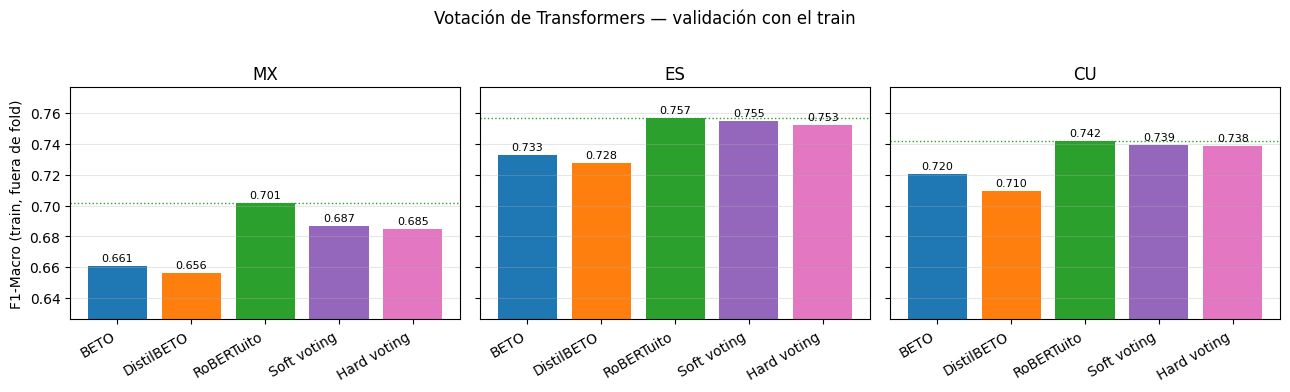

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
orden = [*MODELOS, "Soft voting", "Hard voting"]
colores = ["#1f77b4", "#ff7f0e", "#2ca02c", "#9467bd", "#e377c2"]
for a, v in zip(ax, VARIANTES):
    d = val[val.variante == v].set_index("modelo").loc[orden, "f1_macro"]
    a.bar(range(len(orden)), d.values, color=colores)
    a.axhline(d[MEJOR_INDIVIDUAL], color="#2ca02c", ls=":", lw=1)
    for k, x in enumerate(d.values):
        a.text(k, x + 0.003, f"{x:.3f}", ha="center", fontsize=8)
    a.set_xticks(range(len(orden)), orden, rotation=30, ha="right")
    a.set_title(v.upper()); a.grid(axis="y", alpha=.3)
lo = val.f1_macro.min()
ax[0].set_ylim(lo - 0.03, val.f1_macro.max() + 0.02)
ax[0].set_ylabel("F1-Macro (train, fuera de fold)")
fig.suptitle("Votación de Transformers — validación con el train", y=1.02)
fig.tight_layout()
fig.savefig(OUT_DIR / "votacion_validacion.png", dpi=200, bbox_inches="tight")
fig.savefig(OUT_DIR / "votacion_validacion.pdf", bbox_inches="tight")
plt.show()

## 4. Test oficial

Para cada semilla *s* se combinan las predicciones de la semilla *s* de los tres modelos (5 votaciones por variante). Soft voting usa `prob_ironia_calibrada`; hard voting usa `y_pred` de cada modelo. Se reporta media ± d.e. entre semillas y F1 de la clase irónica.

Igual que en `06_Comparacion_final.ipynb`, el resultado **principal** excluye los tweets del test que también están en el train (unión de las coincidencias detectadas por los tres modelos); `f1_macro_test_completo` usa los 600 tweets (análisis de sensibilidad).

Solo se ejecuta con `EJECUTAR_TEST_VOTACION = True` y `CONFIRMACION_TEST = "TEST_OFICIAL_CONGELADO"` en la sección 2, una sola vez.

In [7]:
CONFIRMACION_TEST = "TEST_OFICIAL_CONGELADO"
EJECUTAR_TEST_VOTACION = True

In [8]:
if not (EJECUTAR_TEST_VOTACION and CONFIRMACION_TEST == "TEST_OFICIAL_CONGELADO"):
    print("Test oficial BLOQUEADO. Se reportan solo los resultados de validación.")
else:
    tablas = []
    for nombre, (carpeta, pref) in MODELOS.items():
        d = pd.read_csv(carpeta / f"{pref}_test_probabilidades.csv")
        d["modelo"] = nombre
        tablas.append(d)
    test = pd.concat(tablas, ignore_index=True)
    filas = []
    for v in VARIANTES:
        for s in sorted(test.seed.unique()):
            sub = test[(test.variante == v) & (test.seed == s)]
            w = sub.pivot(index="ID", columns="modelo", values=["prob_ironia_calibrada", "y_pred", "y_true", "coincide_train"])
            assert len(w) == 600 and w["y_true"].nunique(axis=1).eq(1).all(), f"{v} semilla {s}: IDs o etiquetas no coinciden"
            y = w["y_true"].iloc[:, 0].astype(int).values
            limpio = ~w["coincide_train"].astype(bool).any(axis=1).values  # unión de los tres modelos
            preds = {m: w["y_pred"][m].astype(int).values for m in MODELOS}
            preds["Soft voting"] = (w["prob_ironia_calibrada"][list(MODELOS)].mean(axis=1).values >= UMBRAL).astype(int)
            preds["Hard voting"] = (sum(preds[m] for m in MODELOS) >= 2).astype(int)
            for m, p in preds.items():
                filas.append({"variante": v, "seed": s, "modelo": m,
                              "n_tweets": int(limpio.sum()),
                              "f1_macro": f1m(y[limpio], p[limpio]),
                              "f1_ironia": f1_score(y[limpio], p[limpio], pos_label=1),
                              "f1_macro_test_completo": f1m(y, p)})
    por_semilla = pd.DataFrame(filas)
    por_semilla.to_csv(OUT_DIR / "votacion_test_por_semilla.csv", index=False)
    resumen = (por_semilla.groupby(["variante", "modelo"])
               .agg(f1_macro_mean=("f1_macro", "mean"), f1_macro_std=("f1_macro", "std"),
                    f1_ironia_mean=("f1_ironia", "mean"),
                    f1_ironia_std=("f1_ironia", "std"),
                    f1_test_completo_mean=("f1_macro_test_completo", "mean"),
                    n_tweets=("n_tweets", "first"))
               .reset_index())
    resumen.to_csv(OUT_DIR / "votacion_test_resumen.csv", index=False)
    t = resumen.pivot(index="modelo", columns="variante", values="f1_macro_mean")[VARIANTES]
    t["general"] = t.mean(axis=1)
    display(t.reindex([*MODELOS, "Soft voting", "Hard voting"]).round(4))
    display(resumen.round(4))

variante,mx,es,cu,general
modelo,,,,
BETO,0.7163,0.7311,0.7105,0.7193
DistilBETO,0.7034,0.7281,0.7064,0.7126
RoBERTuito,0.7543,0.7615,0.7327,0.7495
Soft voting,0.7532,0.7582,0.7307,0.7474
Hard voting,0.7409,0.7542,0.7231,0.7394


,variante,modelo,f1_macro_mean,f1_macro_std,f1_ironia_mean,f1_ironia_std,f1_test_completo_mean,n_tweets
0,cu,BETO,0.7105,0.0135,0.6273,0.0157,0.7108,599
1,cu,DistilBETO,0.7064,0.0128,0.6144,0.0211,0.7066,599
2,cu,Hard voting,0.7231,0.0064,0.6292,0.0094,0.7233,599
3,cu,RoBERTuito,0.7327,0.0082,0.6281,0.0137,0.7329,599
4,cu,Soft voting,0.7307,0.0064,0.6376,0.0102,0.7309,599
5,es,BETO,0.7311,0.0073,0.6563,0.0148,0.7374,577
6,es,DistilBETO,0.7281,0.0044,0.6651,0.0062,0.7350,577
7,es,Hard voting,0.7542,0.0048,0.6852,0.0089,0.7599,577
8,es,RoBERTuito,0.7615,0.0098,0.6834,0.0130,0.7667,577
9,es,Soft voting,0.7582,0.0063,0.6887,0.0074,0.7638,577


## 5. Interpretación

- **Validación (train, fuera de fold):** ninguna votación supera a RoBERTuito. En MX la diferencia es negativa y su IC 95 % queda por debajo de 0; en ES y CU el IC incluye el 0, así que la diferencia no es concluyente.
- **Por qué:** los tres modelos se equivocan en muchos de los mismos tweets (acuerdo entre pares de 0.78 a 0.85; DistilBETO es una versión destilada de BETO) y RoBERTuito es claramente mejor que los otros dos, así que BETO y DistilBETO corrigen menos errores de los que añaden.
- **Test oficial:** se mantiene el mismo orden en las tres variantes: RoBERTuito > soft voting > hard voting. La votación queda cerca de RoBERTuito pero no lo mejora.
- **Decisión:** el modelo final sigue siendo **RoBERTuito**. La votación se reporta como resultado complementario (soft como regla principal, hard como secundaria).